<a href="https://colab.research.google.com/github/olexvysotina-cell/ML/blob/main/%D0%9B%D0%A02_3_%D0%92%D0%B8%D1%81%D0%BE%D1%82%D1%96%D0%BD%D0%B0_3_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
from io import StringIO

In [ ]:
url = "https://uk.wikipedia.org/wiki/%D0%9D%D0%B0%D1%81%D0%B5%D0%BB%D0%B5%D0%BD%D0%BD%D1%8F_%D0%A3%D0%BA%D1%80%D0%B0%D1%97%D0%BD%D0%B8#%D0%9D%D0%B0%D1%80%D0%BE%D0%B4%D0%B6%D1%83%D0%B2%D0%B0%D0%BD%D1%96%D1%81%D1%82%D1%8C"
headers = {
"User-Agent": "Mozilla/5.0",
"Accept-Language": "uk-UA,uk;q=0.9,en;q=0.8",
}
html = requests.get(url, headers=headers, timeout=30).text

ukraine_df = pd.read_html(
StringIO(html),
match="Коефіцієнт народжуваності в регіонах України",
thousands=".", decimal=","
)[0]

ukraine_df

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,—,—
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.9,7.6
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.1,10.1
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.1,7.1
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,—
5,Житомирська,26.1,22.3,15.9,12.9,8.9,12.2,12.0,7.9
6,Закарпатська,31.4,27.3,20.7,16.8,11.5,15.1,14.6,10.4
7,Запорізька,21.9,19.7,15.0,12.4,7.1,10.6,10.6,6.8
8,Івано-Франківська,24.3,24.8,18.2,15.5,10.3,12.4,12.2,8.8
9,Київська,20.4,18.9,15.6,12.3,7.3,12.2,12.1,8.0


1. Вивести 5 перших рядків датасету

In [ ]:
ukraine_df.head()

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,—,—
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.9,7.6
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.1,10.1
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.1,7.1
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,—


2. Визначити розмір датасета

In [ ]:
ukraine_df.shape

(28, 9)

In [ ]:
ukraine_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Регіон  28 non-null     object 
 1   1950    26 non-null     float64
 2   1960    27 non-null     float64
 3   1970    27 non-null     float64
 4   1990    28 non-null     float64
 5   2000    28 non-null     float64
 6   2012    28 non-null     float64
 7   2014    28 non-null     object 
 8   2019    28 non-null     object 
dtypes: float64(6), object(3)
memory usage: 2.1+ KB


3. Визначити тип даних

In [ ]:
ukraine_df.dtypes

,0
Регіон,object
1950,float64
1960,float64
1970,float64
1990,float64
2000,float64
2012,float64
2014,object
2019,object


In [ ]:
ukraine_df["2014"] = pd.to_numeric(ukraine_df["2014"], errors="coerce")
ukraine_df["2019"] = pd.to_numeric(ukraine_df["2019"], errors="coerce")

In [ ]:
ukraine_df.dtypes

,0
Регіон,object
1950,float64
1960,float64
1970,float64
1990,float64
2000,float64
2012,float64
2014,float64
2019,float64


4. Переглянути кількість унікальних значень

In [ ]:
ukraine_df.nunique()

,0
Регіон,28
1950,22
1960,25
1970,23
1990,22
2000,21
2012,23
2014,23
2019,18


5. Перевірити наявність пропущених значень При наявності замінити на середнє значення або медіану

In [ ]:
ukraine_df.isna().sum()

,0
Регіон,0
1950,2
1960,1
1970,1
1990,0
2000,0
2012,0
2014,0
2019,0


In [ ]:
ukraine_df = ukraine_df.replace("—", np.nan)

In [ ]:
ukraine_df.isna().sum()

,0
Регіон,0
1950,2
1960,1
1970,1
1990,0
2000,0
2012,0
2014,2
2019,4


In [ ]:
ukraine_df = ukraine_df.fillna(ukraine_df.mean(numeric_only=True))

In [ ]:
ukraine_df.isna().sum()

,0
Регіон,0
1950,0
1960,0
1970,0
1990,0
2000,0
2012,0
2014,0
2019,0


6. Перевірити наявність дублікатів

In [ ]:
ukraine_df.duplicated().sum()

np.int64(0)

7. Провести описову статистику

In [ ]:
ukraine_df.describe()

,1950,1960,1970,1990,2000,2012,2014,2019
count,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000
mean,23.092308,20.748148,15.585185,13.042857,8.207143,11.646429,11.142308,8.020833
std,2.715514,2.881148,1.835394,1.527872,1.556808,1.636274,1.935664,1.338595
min,18.600000,16.300000,12.700000,10.800000,6.100000,9.400000,5.100000,6.000000
25%,21.250000,18.775000,14.400000,12.225000,7.075000,10.450000,10.475000,7.025000
50%,22.900000,20.450000,15.350000,12.600000,7.850000,11.450000,11.142308,8.010417
75%,24.400000,21.925000,16.150000,14.050000,8.950000,12.250000,12.100000,8.725000
max,31.400000,27.300000,20.700000,16.800000,11.800000,15.900000,14.800000,11.000000


8. Створити копію датасету

In [ ]:
df = ukraine_df.copy()


In [ ]:
df = df[ukraine_df["Район"] != "Україна"]

/tmp/ipykernel_1062/3315646232.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  countries["std"] = countries[


,Country,std
1,United States,1.543508e+06


9. Перетворити стовпці на рядки

In [ ]:
df.columns = df.columns.astype(str).str.strip()

In [ ]:
year_cols = [
    col for col in df.columns
    if col != "Регіон"
]

In [ ]:
(df[year_cols].mean().round(2))


,0
1950,23.09
1960,20.75
1970,15.59
1990,13.04
2000,8.21
2012,11.65
2014,11.14
2019,8.02


In [ ]:
(df[year_cols].median().round(2))

,0
1950,22.90
1960,20.45
1970,15.35
1990,12.60
2000,7.85
2012,11.45
2014,11.14
2019,8.01


In [ ]:
(df[year_cols].std().round(2))

,0
1950,2.72
1960,2.88
1970,1.84
1990,1.53
2000,1.56
2012,1.64
2014,1.94
2019,1.34


10. Побудувати діаграму середнього значення показника за роками

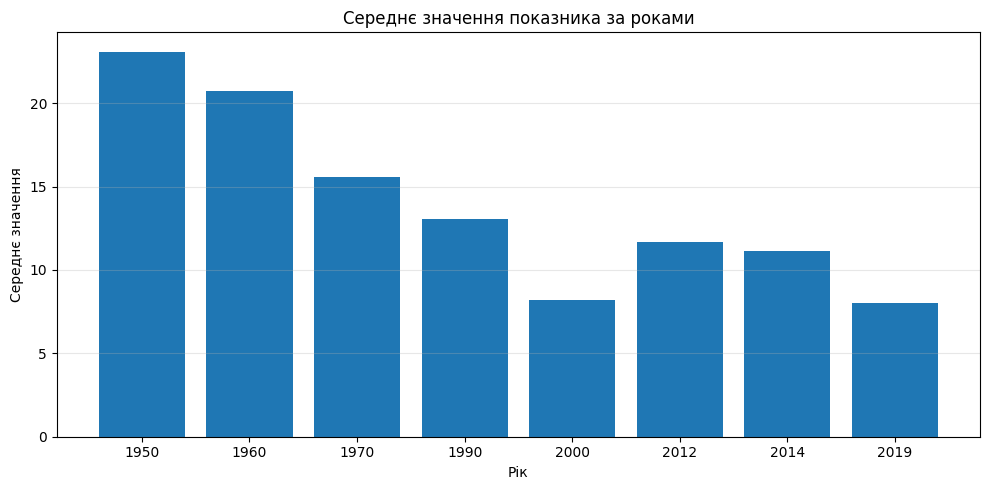

In [ ]:
mean_values = df[year_cols].mean()

plt.figure(figsize=(10, 5))
plt.bar(mean_values.index, mean_values.values)

plt.title("Середнє значення показника за роками")
plt.xlabel("Рік")
plt.ylabel("Середнє значення")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

11. Побудувати діаграму показника за регіонами

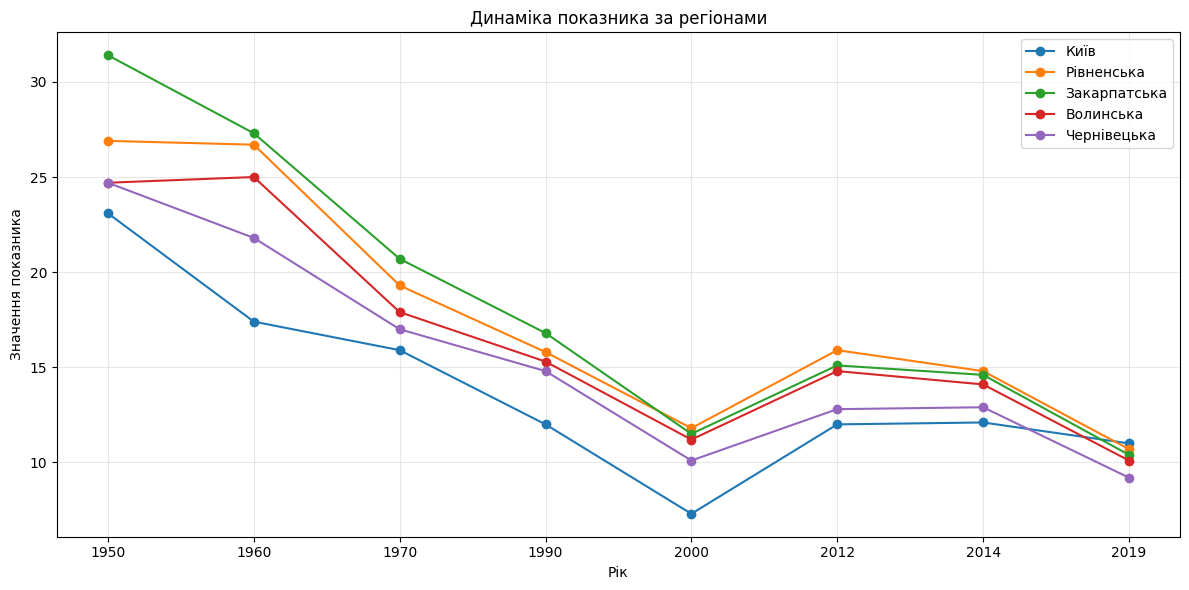

In [ ]:
last_year = year_cols[-1]

top_regions = (
    df.dropna(subset=[last_year])
      .nlargest(5, last_year)["Регіон"]
)

plt.figure(figsize=(12, 6))

for region in top_regions:
    row = df[df["Регіон"] == region].iloc[0]
    plt.plot(
        year_cols,
        row[year_cols],
        marker="o",
        label=region
    )

plt.title("Динаміка показника за регіонами")
plt.xlabel("Рік")
plt.ylabel("Значення показника")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


12. Топ 10 регіонів за народжуваністю в 2019 році

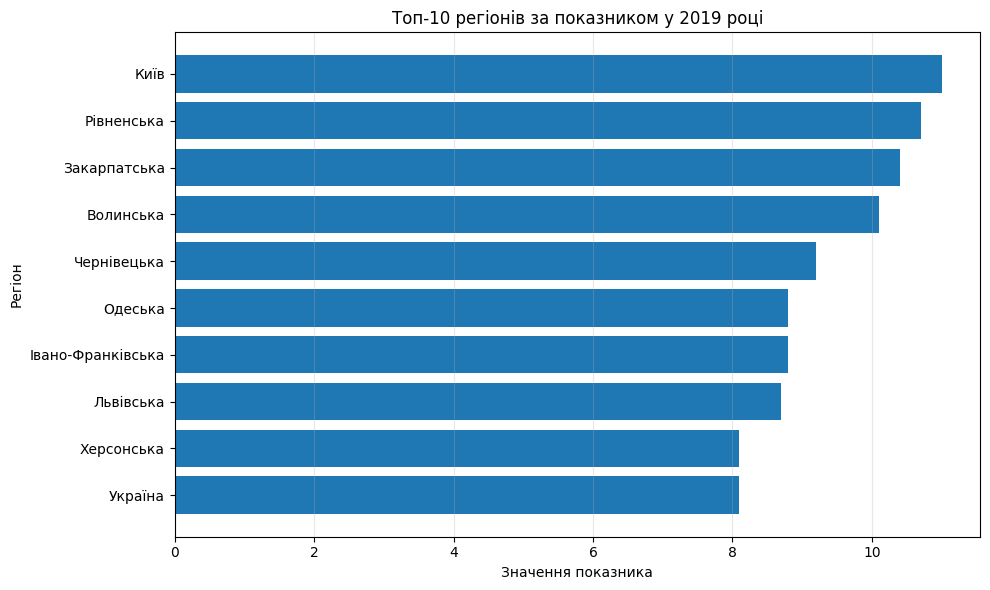

In [ ]:

top10 = (
    df[["Регіон", last_year]]
    .dropna()
    .nlargest(10, last_year)
    .sort_values(last_year)
)

plt.figure(figsize=(10, 6))
plt.barh(top10["Регіон"], top10[last_year])

plt.title(f"Топ-10 регіонів за показником у {last_year} році")
plt.xlabel("Значення показника")
plt.ylabel("Регіон")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


13. Розподіл значень показника за 2019 рік

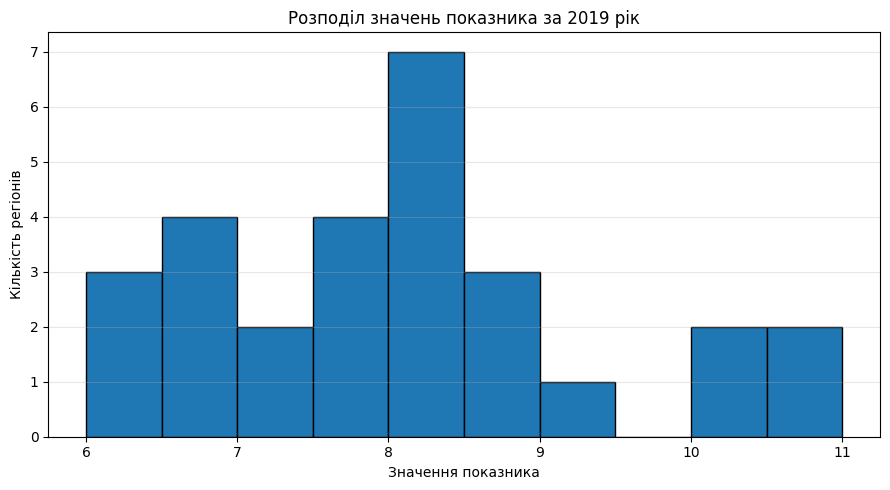

In [ ]:

values = df[last_year].dropna()

plt.figure(figsize=(9, 5))
plt.hist(values, bins=10, edgecolor="black")

plt.title(f"Розподіл значень показника за {last_year} рік")
plt.xlabel("Значення показника")
plt.ylabel("Кількість регіонів")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


14. Порівняння показників за 1950 і 2019 рокі

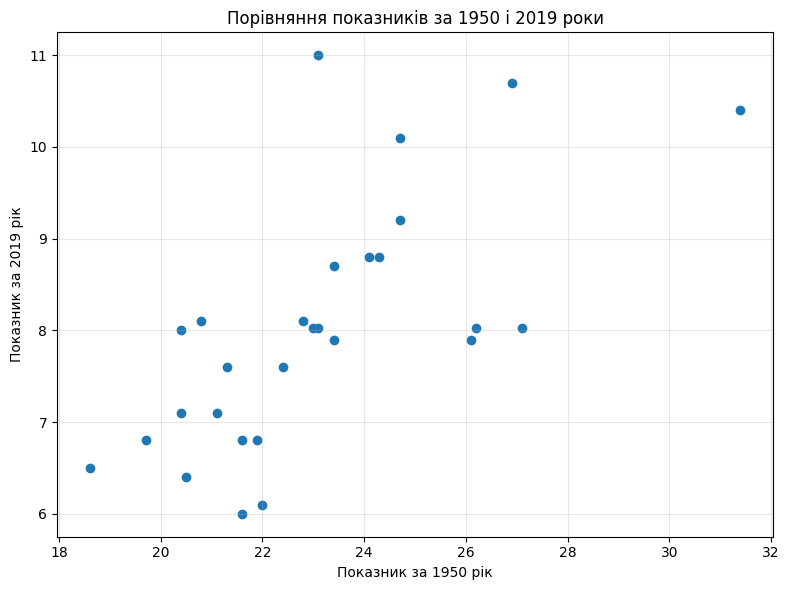

In [ ]:

plt.figure(figsize=(8, 6))

plt.scatter(df["1950"], df["2019"])

plt.title("Порівняння показників за 1950 і 2019 роки")
plt.xlabel("Показник за 1950 рік")
plt.ylabel("Показник за 2019 рік")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


1. Датасет містить 28 рядків і 9 стовпців.
2. За середнім значенням народжуваність у період з 1950 до 2019 зменшилась
3. За найбільшими значеннями областей у 1950 переважає Закарпатська область, а в 2019 році Київська область.